# Bài 4: K láng giềng gần nhất (KNN)


In [4]:
import os, shutil

os.makedirs("data", exist_ok=True)
can = {"sinh_vien": "sinh_vien_mo_rong.csv",
       "hai_vang": "hai_vang_trang.csv",
       "gia_nha": "gia_nha.csv"}

if not all(os.path.exists("data/" + t) for t in can.values()):
    from google.colab import files
    up = files.upload()
    for ten in up:
        for khoa, dich in can.items():
            if khoa in ten:
                shutil.move(ten, "data/" + dich)

print(sorted(os.listdir("data")))

['gia_nha.csv', 'hai_vang_trang.csv', 'sinh_vien_mo_rong.csv']


## 2. Khoảng cách và láng giềng (`e1_khoang_cach.py`)

In [5]:
import numpy as np
import pandas as pd

# Ba bạn: A và C học gần như y hệt nhau, B học khác hẳn
ba_ban = {
    "A": np.array([5.0, 3.0, 4000.0]),
    "B": np.array([25.0, 9.0, 4100.0]),
    "C": np.array([6.0, 3.5, 7000.0]),
}


def kc(u, v):
    """Khoang cach Euclid giua hai diem."""
    return np.sqrt(((u - v) ** 2).sum())


print("Khoang cach KHI CHUA chuan hoa")
print(f"  d(A, B) = {kc(ba_ban['A'], ba_ban['B']):8.1f}")
print(f"  d(A, C) = {kc(ba_ban['A'], ba_ban['C']):8.1f}")
print()

# Chuẩn hoá bằng trung bình và độ lệch chuẩn của cả bộ dữ liệu
df = pd.read_csv("data/sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]].to_numpy(dtype=float)
tb = X.mean(axis=0)
dl = X.std(axis=0)
print("Do lech chuan cua ba cot:")
print(f"  gio_on {dl[0]:.2f}  diem_giua_ky {dl[1]:.2f}"
      f"  chi_tieu {dl[2]:.0f}")
print()

chuan = {ten: (v - tb) / dl for ten, v in ba_ban.items()}
print("Khoang cach SAU KHI chuan hoa")
print(f"  d(A, B) = {kc(chuan['A'], chuan['B']):.2f}")
print(f"  d(A, C) = {kc(chuan['A'], chuan['C']):.2f}")
print()

# Tìm 5 láng giềng gần nhất của một bạn mới, chỉ dùng hai cột học tập
X2 = df[["gio_on", "diem_giua_ky"]].to_numpy(dtype=float)
y = df["qua_mon"].to_numpy()
tb2, dl2 = X2.mean(axis=0), X2.std(axis=0)
ban_moi = np.array([12.0, 6.5])
X2c = (X2 - tb2) / dl2
moi_c = (ban_moi - tb2) / dl2
khoang = np.sqrt(((X2c - moi_c) ** 2).sum(axis=1))
gan = np.argsort(khoang)[:5]

print("Ban moi: on 12 gio, diem giua ky 6.5")
print("Nam lang gieng gan nhat:")
for i in gan:
    ket = "qua" if y[i] == 1 else "rot"
    print(f"  gio {X2[i, 0]:5.1f}  diem {X2[i, 1]:4.1f}  "
          f"khoang cach {khoang[i]:.3f} -> {ket}")
so_qua = int(y[gan].sum())
print(f"Bo phieu: {so_qua} qua, {5 - so_qua} rot")
print("Du doan:", "qua mon" if so_qua >= 3 else "rot mon")

Khoang cach KHI CHUA chuan hoa
  d(A, B) =    102.2
  d(A, C) =   3000.0

Do lech chuan cua ba cot:
  gio_on 7.82  diem_giua_ky 2.09  chi_tieu 1692

Khoang cach SAU KHI chuan hoa
  d(A, B) = 3.85
  d(A, C) = 1.79

Ban moi: on 12 gio, diem giua ky 6.5
Nam lang gieng gan nhat:
  gio  10.5  diem  6.4  khoang cach 0.198 -> qua
  gio  12.5  diem  6.1  khoang cach 0.202 -> qua
  gio  14.0  diem  6.4  khoang cach 0.260 -> qua
  gio   9.5  diem  6.1  khoang cach 0.373 -> rot
  gio  10.5  diem  5.8  khoang cach 0.386 -> qua
Bo phieu: 4 qua, 1 rot
Du doan: qua mon


## 3. Chuẩn hoá, bước không được bỏ qua (`e2_chuan_hoa.py`)

In [6]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_mo_rong.csv")
y = df["qua_mon"]

X3 = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
X_tr, X_te, y_tr, y_te = train_test_split(
    X3, y, test_size=0.25, random_state=17, stratify=y
)


def cham(mo_hinh, cot):
    mo_hinh.fit(X_tr[cot], y_tr)
    return accuracy_score(y_te, mo_hinh.predict(X_te[cot]))


def knn_chuan():
    """KNN co chuan hoa, gop lam mot khoi bang pipeline."""
    return make_pipeline(StandardScaler(), KNeighborsClassifier(7))


ba_cot = ["gio_on", "diem_giua_ky", "chi_tieu"]
hai_cot = ["gio_on", "diem_giua_ky"]

a = cham(KNeighborsClassifier(n_neighbors=7), ba_cot)
b = cham(knn_chuan(), ba_cot)
c = cham(knn_chuan(), hai_cot)

print(f"Doan bua ca lop qua          : {y_te.mean():.4f}")
print(f"Ba cot, khong chuan hoa      : {a:.4f}")
print(f"Ba cot, co chuan hoa         : {b:.4f}")
print(f"Bo cot chi_tieu, co chuan hoa: {c:.4f}")

Doan bua ca lop qua          : 0.6000
Ba cot, khong chuan hoa      : 0.5333
Ba cot, co chuan hoa         : 0.8667
Bo cot chi_tieu, co chuan hoa: 0.9000


## 4. Chọn số láng giềng (`e3_chon_k.py`)

In [7]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Hai cột x1 và x2 có thang đo gần nhau nên ở bộ này không chuẩn hoá cũng được.
print("Accuracy tren tap hoc va tap kiem tra theo k")
print("   k  tap hoc  tap kiem tra")
for k in [1, 5, 13, 31, 101]:
    mh = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f" {k:3d}   {a_hoc:.4f}   {a_kt:.4f}")
print()

# Chọn k chỉ dựa trên tập học, không nhìn tập kiểm tra
print("Kiem dinh cheo 5 phan tren tap hoc:")
diem = {}
for k in range(1, 52, 2):
    diem[k] = cross_val_score(KNeighborsClassifier(n_neighbors=k),
                              X_tr, y_tr, cv=5).mean()
k_tot = max(diem, key=diem.get)
for k in [1, 5, 9, 13, 17, 25, 51]:
    dau = "  <- tot nhat" if k == k_tot else ""
    print(f"  k = {k:2d}  diem trung binh {diem[k]:.4f}{dau}")
print()

# Chọn xong mới mở tập kiểm tra, và chỉ mở một lần
mh = KNeighborsClassifier(n_neighbors=k_tot).fit(X_tr, y_tr)
print(f"k tot nhat = {k_tot}")
acc = accuracy_score(y_te, mh.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

Accuracy tren tap hoc va tap kiem tra theo k
   k  tap hoc  tap kiem tra
   1   1.0000   0.8000
   5   0.8756   0.9067
  13   0.8844   0.9200
  31   0.8667   0.8933
 101   0.8311   0.8533

Kiem dinh cheo 5 phan tren tap hoc:
  k =  1  diem trung binh 0.7778
  k =  5  diem trung binh 0.8444
  k =  9  diem trung binh 0.8444
  k = 13  diem trung binh 0.8667  <- tot nhat
  k = 17  diem trung binh 0.8533
  k = 25  diem trung binh 0.8622
  k = 51  diem trung binh 0.8533

k tot nhat = 13
Accuracy tren tap kiem tra = 0.9200


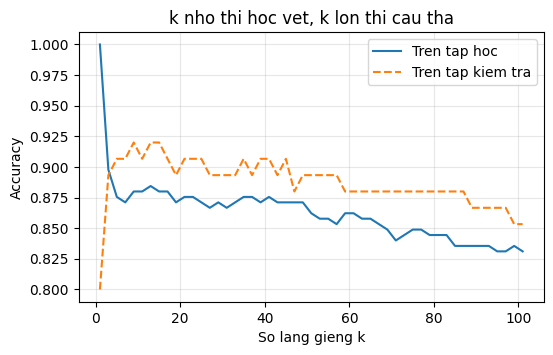

In [8]:
import matplotlib.pyplot as plt

ks = list(range(1, 102, 2))
hoc, kt = [], []
for k in ks:
    mh = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    hoc.append(accuracy_score(y_tr, mh.predict(X_tr)))
    kt.append(accuracy_score(y_te, mh.predict(X_te)))

plt.figure(figsize=(6, 3.5))
plt.plot(ks, hoc, label="Tren tap hoc")
plt.plot(ks, kt, "--", label="Tren tap kiem tra")
plt.xlabel("So lang gieng k")
plt.ylabel("Accuracy")
plt.title("k nho thi hoc vet, k lon thi cau tha")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. So với các mô hình đã học (`e4_so_sanh.py`)

In [9]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cac_mo_hinh = [
    ("Hoi quy logistic", LogisticRegression()),
    ("Naive Bayes     ", GaussianNB()),
    ("KNN, k = 13     ", KNeighborsClassifier(n_neighbors=13)),
]

print("Accuracy tren tap kiem tra, bo hai vang trang")
for ten, mh in cac_mo_hinh:
    mh.fit(X_tr, y_tr)
    print(f"  {ten}: {accuracy_score(y_te, mh.predict(X_te)):.4f}")

Accuracy tren tap kiem tra, bo hai vang trang
  Hoi quy logistic: 0.8533
  Naive Bayes     : 0.8533
  KNN, k = 13     : 0.9200


## 6. KNN cho bài toán hồi quy (`e5_knn_hoi_quy.py`)

In [10]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# Cùng cách chia với bài 1 để so sánh công bằng
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42)

knn = KNeighborsRegressor(n_neighbors=5).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print("MAE tren tap kiem tra (ty dong)")
mae_knn = mean_absolute_error(y_te, knn.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f"  KNN, k = 5  : {mae_knn:.4f}")
print(f"  Duong thang : {mae_duong:.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print("  dien tich    KNN   duong thang")
for dt, a, b in zip(can_moi["dien_tich"], knn.predict(can_moi),
                    duong.predict(can_moi)):
    print(f"  {dt:6.0f} m2  {a:6.2f}  {b:6.2f}")
print()

# Năm láng giềng của căn 250 m2 chính là những căn rộng nhất đã thấy
_, chi_so = knn.kneighbors(pd.DataFrame({"dien_tich": [250.0]}))
lg = X_tr.iloc[chi_so[0]]["dien_tich"].tolist()
print("Nam lang gieng cua can 250 m2:", ", ".join(f"{v:.1f}" for v in lg))

MAE tren tap kiem tra (ty dong)
  KNN, k = 5  : 0.4030
  Duong thang : 0.2578

Du doan cho bon can moi (ty dong)
  dien tich    KNN   duong thang
      60 m2    4.95    5.12
     100 m2    8.32    8.24
     150 m2    9.32   12.13
     250 m2    9.32   19.91

Nam lang gieng cua can 250 m2: 117.5, 115.9, 111.7, 111.2, 104.2


Vẽ đường dự đoán của KNN và đường thẳng (Hình 7 trong đề):

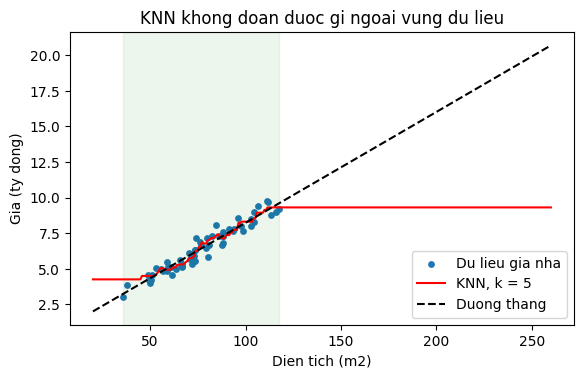

In [11]:
import numpy as np
import matplotlib.pyplot as plt

xs = pd.DataFrame({"dien_tich": np.linspace(20, 260, 300)})
plt.figure(figsize=(6.5, 3.8))
plt.scatter(X["dien_tich"], y, s=15, label="Du lieu gia nha")
plt.plot(xs["dien_tich"], knn.predict(xs), "r-", label="KNN, k = 5")
plt.plot(xs["dien_tich"], duong.predict(xs), "k--", label="Duong thang")
plt.axvspan(X["dien_tich"].min(), X["dien_tich"].max(), color="green", alpha=0.07)
plt.xlabel("Dien tich (m2)")
plt.ylabel("Gia (ty dong)")
plt.title("KNN khong doan duoc gi ngoai vung du lieu")
plt.legend()
plt.show()

---
# 7. Bài tập

### Bài tập 1: Tự viết KNN không dùng thư viện
Viết `knn_du_doan(X_hoc, y_hoc, x_moi, k)`, dự đoán cho toàn bộ tập kiểm tra của bộ hai vầng trăng với k = 13, rồi so với `KNeighborsClassifier`.

In [12]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]].to_numpy(dtype=float)
y = df["nhan"].to_numpy()
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def knn_du_doan(X_hoc, y_hoc, x_moi, k):
    """Du doan nhan cua mot mau moi bang k lang gieng gan nhat."""
    khoang = np.sqrt(((X_hoc - x_moi) ** 2).sum(axis=1))   # buoc 1
    gan = np.argsort(khoang)[:k]                           # buoc 2
    so_phieu = np.bincount(y_hoc[gan].astype(int))         # buoc 3
    return np.argmax(so_phieu)


du_doan = np.array([knn_du_doan(X_tr, y_tr, x, 13) for x in X_te])
acc_tu_viet = (du_doan == y_te).mean()

sk = KNeighborsClassifier(n_neighbors=13).fit(X_tr, y_tr)
acc_sklearn = (sk.predict(X_te) == y_te).mean()

print(f"Accuracy tu viet : {acc_tu_viet:.4f}")
print(f"Accuracy sklearn : {acc_sklearn:.4f}")
print("Hai con so bang nhau:", np.isclose(acc_tu_viet, acc_sklearn))

Accuracy tu viet : 0.9200
Accuracy sklearn : 0.9200
Hai con so bang nhau: True


**Nhận xét:** hàm tự viết cho accuracy 0.9200, bằng đúng `KNeighborsClassifier`. Ba bước nằm ngay trong hàm: (1) tính khoảng cách Euclid từ mẫu mới tới mọi mẫu học, (2) `np.argsort` lấy chỉ số của k khoảng cách nhỏ nhất, (3) cho k láng giềng bỏ phiếu bằng `np.bincount` rồi lấy lớp nhiều phiếu nhất.

### Bài tập 2: Khoảng cách Manhattan
Chạy lại `e3_chon_k.py` với `metric="manhattan"` rồi so với Euclid.

In [13]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def chon_k_va_cham(metric):
    diem = {}
    for k in range(1, 52, 2):
        mh = KNeighborsClassifier(n_neighbors=k, metric=metric)
        diem[k] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    k_tot = max(diem, key=diem.get)
    mh = KNeighborsClassifier(n_neighbors=k_tot, metric=metric).fit(X_tr, y_tr)
    return k_tot, diem[k_tot], accuracy_score(y_te, mh.predict(X_te))


print("Khoang cach   k tot nhat  diem CV  accuracy kiem tra")
for ten in ["euclidean", "manhattan"]:
    k_tot, d_cv, acc = chon_k_va_cham(ten)
    print(f"{ten:12s}  {k_tot:8d}   {d_cv:.4f}   {acc:.4f}")

Khoang cach   k tot nhat  diem CV  accuracy kiem tra
euclidean           13   0.8667   0.9200
manhattan           27   0.8667   0.9067


**Nhận xét:** Euclid chọn k = 13, Manhattan chọn k = 27, nhưng điểm kiểm định chéo của hai cách bằng nhau (0.8667). Accuracy kiểm tra 0.9200 so với 0.9067, chênh đúng 1 mẫu trên 75 mẫu kiểm tra. Vậy đổi cách đo khoảng cách ở bộ này gần như không làm kết quả khác đi.

### Bài tập 3: Đổi đơn vị đo
Đổi `chi_tieu` từ nghìn đồng sang triệu đồng (chia 1000), chạy KNN k = 7 không chuẩn hoá trên ba cột.

In [14]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_mo_rong.csv")
y = df["qua_mon"]
cot = ["gio_on", "diem_giua_ky", "chi_tieu"]

df_trieu = df.copy()
df_trieu["chi_tieu"] = df_trieu["chi_tieu"] / 1000      # nghin dong -> trieu dong


def chia_va_cham(du_lieu, chuan_hoa):
    X_tr, X_te, y_tr, y_te = train_test_split(
        du_lieu[cot], y, test_size=0.25, random_state=17, stratify=y
    )
    if chuan_hoa:
        mh = make_pipeline(StandardScaler(), KNeighborsClassifier(7))
    else:
        mh = KNeighborsClassifier(n_neighbors=7)
    mh.fit(X_tr, y_tr)
    return accuracy_score(y_te, mh.predict(X_te))


print("                         nghin dong   trieu dong")
print(f"Khong chuan hoa          {chia_va_cham(df, False):.4f}       {chia_va_cham(df_trieu, False):.4f}")
print(f"Co chuan hoa             {chia_va_cham(df, True):.4f}       {chia_va_cham(df_trieu, True):.4f}")

                         nghin dong   trieu dong
Khong chuan hoa          0.5333       0.8667
Co chuan hoa             0.8667       0.8667


**Nhận xét:** accuracy nhảy từ 0.5333 lên 0.8667 chỉ nhờ đổi đơn vị. Lý do: KNN dựa hoàn toàn vào khoảng cách. Khi `chi_tieu` tính bằng nghìn đồng, độ lệch chuẩn của nó là 1692, nuốt hết hai cột còn lại (7.82 và 2.09). Chia cho 1000 thì độ lệch chuẩn còn khoảng 1.69, ngang ngửa hai cột kia nên không còn một mình quyết định khoảng cách.

Nếu **có chuẩn hoá** thì đổi đơn vị không làm kết quả thay đổi (cả hai cột đều 0.8667), vì chia cả cột cho 1000 rồi chuẩn hoá thì ra đúng các giá trị chuẩn hoá như cũ.

### Bài tập 4: Láng giềng có trọng số
Thêm `weights="distance"`, chạy k = 1, 13, 101 trên bộ hai vầng trăng và so với bảng ở mục 4.

In [15]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("                 uniform (mac dinh)      distance")
print("   k           hoc     kiem tra      hoc     kiem tra")
for k in [1, 13, 101]:
    kq = []
    for w in ["uniform", "distance"]:
        mh = KNeighborsClassifier(n_neighbors=k, weights=w).fit(X_tr, y_tr)
        kq += [accuracy_score(y_tr, mh.predict(X_tr)),
               accuracy_score(y_te, mh.predict(X_te))]
    print(f" {k:3d}         {kq[0]:.4f}    {kq[1]:.4f}      {kq[2]:.4f}    {kq[3]:.4f}")

                 uniform (mac dinh)      distance
   k           hoc     kiem tra      hoc     kiem tra
   1         1.0000    0.8000      1.0000    0.8000
  13         0.8844    0.9200      1.0000    0.9333
 101         0.8311    0.8533      1.0000    0.9067


**Nhận xét:** với k = 1 không đổi gì. Với k = 13, accuracy kiểm tra tăng nhẹ từ 0.9200 lên 0.9333. Với k = 101 tăng từ 0.8533 lên 0.9067, tức là có giúp mô hình bớt cẩu thả. Lý do: khi láng giềng gần có phiếu nặng và láng giềng xa có phiếu rất nhẹ, kết quả chủ yếu do vài người hàng xóm gần nhất quyết định, nên k lớn không còn làm biên bị "làm phẳng" quá mức.

Hai lưu ý: accuracy trên tập học luôn bằng 1.0000 vì khoảng cách của một điểm tới chính nó là 0 nên phiếu của nó nặng vô hạn, con số này vô nghĩa. Ngoài ra tập kiểm tra chỉ có 75 mẫu, chênh vài mẫu là chuyện thường, đừng kết luận quá mạnh.

### Bài tập 5: Chọn k cho bài toán hồi quy
Dùng kiểm định chéo 5 phần trên tập học, k từ 1 tới 20, `scoring="neg_mean_absolute_error"`.

In [16]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

mae_cv = {}
for k in range(1, 21):
    diem = cross_val_score(KNeighborsRegressor(n_neighbors=k), X_tr, y_tr,
                           cv=5, scoring="neg_mean_absolute_error")
    mae_cv[k] = -diem.mean()          # diem tra ve mang dau am nen doi dau lai

k_tot = min(mae_cv, key=mae_cv.get)
print("MAE kiem dinh cheo theo k:")
for k in sorted({1, 2, 3, 5, 7, 10, 15, 20, k_tot}):
    dau = "  <- tot nhat" if k == k_tot else ""
    print(f"  k = {k:2d}  {mae_cv[k]:.4f}{dau}")

knn = KNeighborsRegressor(n_neighbors=k_tot).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)
mae_knn = mean_absolute_error(y_te, knn.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print()
print(f"k tot nhat = {k_tot}")
print(f"MAE kiem tra, KNN k = {k_tot}: {mae_knn:.4f}")
print(f"MAE kiem tra, duong thang : {mae_duong:.4f}")
print("KNN vuot duoc duong thang:", mae_knn < mae_duong)

MAE kiem dinh cheo theo k:
  k =  1  0.4164
  k =  2  0.3498  <- tot nhat
  k =  3  0.3714
  k =  5  0.3816
  k =  7  0.3990
  k = 10  0.4365
  k = 15  0.5290
  k = 20  0.6254

k tot nhat = 2
MAE kiem tra, KNN k = 2: 0.4867
MAE kiem tra, duong thang : 0.2578
KNN vuot duoc duong thang: False


**Nhận xét:** kiểm định chéo chọn k = 2 (MAE trung bình 0.3498). Nhưng trên tập kiểm tra MAE là 0.4867, vẫn **không vượt** đường thẳng (0.2578). Vì giá nhà tăng gần như thẳng theo diện tích nên đường thẳng giả định đúng, còn KNN chỉ trung bình vài căn xung quanh nên dao động hơn, và còn không ngoại suy được ra ngoài vùng dữ liệu.

### Bài tập 6: Đo thời gian dự đoán
Tạo dữ liệu ngẫu nhiên 2 đặc trưng với 1000, 10000, 100000 mẫu; đo `.fit` và `.predict` cho 1000 mẫu mới. Mình đo cả hai kiểu tìm láng giềng: mặc định của sklearn (`auto`, dùng cây KD nên nhanh hơn) và `brute` (so với toàn bộ dữ liệu, đúng như KNN thuần mô tả trong bài).

In [17]:
import time
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

rng = np.random.default_rng(0)
X_moi = rng.random((1000, 2))


def do_thoi_gian(n, thuat_toan):
    X = rng.random((n, 2))
    y = (X[:, 0] + X[:, 1] > 1).astype(int)
    mh = KNeighborsClassifier(n_neighbors=5, algorithm=thuat_toan)

    t0 = time.perf_counter()
    mh.fit(X, y)
    t_fit = time.perf_counter() - t0

    t0 = time.perf_counter()
    mh.predict(X_moi)
    t_pred = time.perf_counter() - t0
    return t_fit, t_pred


for thuat_toan in ["auto", "brute"]:
    print(f"algorithm = {thuat_toan}")
    print("    so mau     fit (giay)   predict 1000 mau (giay)")
    for n in [1000, 10000, 100000]:
        t_fit, t_pred = do_thoi_gian(n, thuat_toan)
        print(f"   {n:7d}     {t_fit:9.5f}     {t_pred:9.5f}")
    print()

algorithm = auto
    so mau     fit (giay)   predict 1000 mau (giay)
      1000       0.00166       0.00711
     10000       0.00649       0.00612
    100000       0.07840       0.01038

algorithm = brute
    so mau     fit (giay)   predict 1000 mau (giay)
      1000       0.00093       0.00989
     10000       0.00128       0.08048
    100000       0.00551       0.51721



**Nhận xét:** với `brute`, `.fit` gần như không tốn gì (chỉ cất dữ liệu), còn `.predict` tăng gần tỷ lệ thuận với số mẫu: khi dữ liệu tăng 10 lần thì thời gian dự đoán tăng cỡ 8 đến 10 lần. Đó chính là "học lười": huấn luyện tức thì, mọi phép tính dồn sang lúc dự đoán. Với `auto`, sklearn dựng sẵn cây KD lúc `.fit` nên `.predict` nhanh hơn nhiều ở 2 đặc trưng, nhưng bản chất vẫn là giữ nguyên toàn bộ dữ liệu. (Con số thời gian mỗi máy mỗi khác, chỉ cần so tương đối giữa các cỡ.)